# Homework08

Exercises to practice pandas, data analysis and classification

## Goals

- Understand the effects of pre-processing data
- Get familiar with the ML flow: encode -> normalize -> train -> evaluate
- Understand the difference between regression and classification tasks
- Build intuition for different classification models

### Setup

Run the following 2 cells to import all necessary libraries and helpers for this homework.

In [ ]:
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/image_utils.py" -O image_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/Homework08/raw/main/Homework08_utils.pyc" -O Homework08_utils.pyc

!wget -qO- https://github.com/PSAM-5020-2026F-A/5020-utils/releases/latest/download/0801-500.tar.gz | tar xz

In [ ]:
import pandas as pd
import PIL.Image as PImage

from os import listdir, path

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from data_utils import classification_error, display_confusion_matrix, regression_error

from image_utils import get_pixels, make_image

from Homework08_utils import CamUtils

## Classification

The dataset we are going to use has images from $25$ different security cameras, and our task is to separate them by camera. Some of the cameras move, some of them don't, and there are more than $1000$ images, so there's no way we want to do this by hand.

### Loading Data

If we look at the images in `./data/image/0801-500/train/`, we'll notice that they are named and organized in a very particular way. They're all in the same directory and the first part of their filename specifies which camera they came from. Even though those `ids` are numbers, they're not sequential, so we'll use some helper functions to extract a unique `label` from their filenames.

This is exactly what the `OrdinalEncoder` class does, but since we only have to encode this one column, we'll do it by hand while we read the files in.

Alternatively, we could try using a `OneHotEncoder`, but since we have $25$ cameras, adding $25$ sparse columns to our dataset might confuse our classification fitting.

In [ ]:
# this creates a list of all the files in a given directory, that end in .jpg
train_files = [f for f in listdir("./data/image/0801-500/train") if f.endswith(".jpg")]

In [ ]:
import os

# Let's fix the path to use the correct local directory relative to /content
train_dir = "./data/image/0801-500/train"

# Let's verify the path exists and check its content

files = sorted([os.path.join(train_dir, f) for f in os.listdir(train_dir) if f.endswith(".jpg")])


Now we'll read the image pixels and extract their labels. `CamUtils.get_label()` is the helper function we'll use to "encode" and return a label id based on the filename.

In [ ]:
pixel_data = []
label_data = []

for fname in train_files:
  label = CamUtils.get_label(fname)
  img = PImage.open(path.join("./data/image/0801-500/train", fname))
  pixel_data.append(get_pixels(img))
  label_data.append(label)

In [ ]:
# TODO: check if labels got extracted correctly by looking at
#       the first few items of the label list and the filename list

for i in range(10):
    print(f"Filename: {train_files[i]} -> Label: {label_data[i]}")
    print(f"Filename: {train_files[i]} -> Pixels: {pixel_data[i]}")

Filename: 22-43.jpg -> Label: 17
Filename: 22-43.jpg -> Pixels: [134, 134, 134, 134, 134, 134, 134, 134, 135, 135, 135, 135, 135, 135, 135, 135, 137, 137, 137, 137, 137, 137, 137, 137, 139, 139, 139, 138, 138, 137, 137, 137, 138, 138, 138, 138, 138, 138, 138, 138, 139, 139, 139, 140, 140, 140, 141, 141, 141, 141, 141, 141, 141, 141, 141, 141, 143, 143, 143, 143, 143, 143, 143, 143, 144, 144, 145, 145, 145, 146, 146, 146, 146, 146, 145, 144, 143, 143, 142, 142, 149, 149, 149, 149, 149, 149, 149, 149, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 149, 149, 149, 150, 150, 151, 151, 151, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 149, 149, 148, 148, 148, 144, 145, 145, 146, 147, 148, 149, 149, 152, 152, 151, 151, 151, 150, 150, 150, 151, 151, 152, 153, 153, 153, 152, 152, 150, 150, 150, 150, 150, 150, 150, 150, 149, 149, 148, 148, 148, 147, 147, 147, 148, 148, 148, 148, 148, 148, 148, 148, 147, 147, 147, 147, 147, 147, 147, 147, 148, 148, 148, 

The labels and the filenames won't match exactly since labels start at $0$ and the filenames start at $01$ and skip some numbers.

We can open some images from pixels, just to make sure we loaded them correctly (they're squares, so no need to specify `width`):

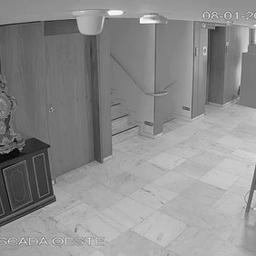

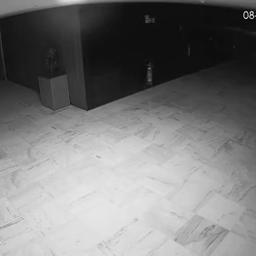

In [ ]:
display(make_image(pixel_data[0]))
display(make_image(pixel_data[10]))

And now might not be a bad time to peek into the `data/image/0801-500/` directories to see what's inside them and what the images look like.... and get to know the data...

### DataFrame it

Let's put our raw pixel data into a `DataFrame`, and create a column for storing each image's label.

(this next cell might take a while to run)

In [ ]:
train_df = pd.DataFrame(pixel_data)
train_df["label"] = label_data

Let's inspect our `DataFrame`:

In [ ]:
train_df.head()

,0,1,2,3,4,5,6,7,8,9,...,65527,65528,65529,65530,65531,65532,65533,65534,65535,label
0,134,134,134,134,134,134,134,134,135,135,...,170,166,165,165,163,160,156,153,151,17
1,52,56,62,66,67,66,64,63,70,75,...,171,170,170,171,174,177,175,169,164,0
2,64,66,68,69,73,86,103,116,101,95,...,63,65,65,66,67,67,67,66,66,5
3,170,170,170,170,170,170,170,170,171,171,...,130,104,102,99,97,96,97,97,98,21
4,100,100,100,100,100,100,100,100,101,101,...,128,124,120,115,113,115,118,118,118,23


### Insight

<span style="color:hotpink">
Does anything stand out as peculiar about the feature values in our <code>DataFrame</code>?<br>
Do we have to encode or scale our data?<br>
Why? Or, why not?<br>
</span>

<span style="color:lavender;">rows hold similar ranges of data, perhaps a feature of the relatively static view from the camera?</span>

### Test Files

If that worked, repeat the process for the test files inside the `./data/image/0801-500/test/` directory.

We can almost use the exact same steps as we did above to create a `DataFrame`, the only difference being that we don't have labels for these images.

In [ ]:
# TODO: create a list of files in the test/ directory
test_files = sorted([f for f in listdir("./data/image/0801-500/test") if f.endswith(".jpg")])

# TODO: check its length and content
print(f"Found {len(test_files)} test images.")

test_pixel_data = []

# TODO: loop over files and load their pixels into a list
for fname in test_files:
    test_img = PImage.open(path.join("./data/image/0801-500/test", fname))
    test_pixel_data.append(get_pixels(test_img))

# TODO: load into DataFrame (this might take 20 - 30 seconds)
test_df = pd.DataFrame(test_pixel_data)

# Let's verify the shape of our new test DataFrame
print("Test DataFrame shape:", test_df.shape)

Found 1573 test images.
Test DataFrame shape: (1573, 65536)


Check the `DataFrame`

In [ ]:
test_df.head()

,0,1,2,3,4,5,6,7,8,9,...,65526,65527,65528,65529,65530,65531,65532,65533,65534,65535
0,6,7,8,8,9,9,8,8,9,9,...,164,168,156,149,158,180,185,174,177,193
1,58,60,48,54,58,56,65,57,57,57,...,194,194,196,197,196,194,192,191,192,193
2,248,248,248,249,249,249,250,250,247,247,...,52,64,51,51,58,62,54,41,40,50
3,199,157,117,107,111,112,111,113,115,122,...,181,177,186,184,182,178,171,168,176,188
4,94,94,94,94,94,94,94,94,95,95,...,92,92,92,96,89,83,87,85,81,87


Looks like data!!

We could train a `RandomForestClassifier` directly on this `DataFrame` and see what would happen, but my guess is that Python runs out of memory and crashes our tab/browser/computer...

We'll use _projection_ to reduce the number of dimensions in our dataset. Projection is when we just drop some of the columns in our dataset.

Which columns ? That's up to us.

Let's first try using the first $N$ columns/features where $N$ is a number around $10$.

This is how we get the first $N$ columns from a `DataFrame`:

In [ ]:
# split input and output features
NUM_FEATURES = 10
chosen_columns = train_df.columns[:NUM_FEATURES]
train_features = train_df[chosen_columns]

out_features = train_df["label"]

# also separate test dataset features
test_features = test_df[chosen_columns]

From our [Week 08](https://github.com/PSAM-5020-2026F-A/WK08) notebook, we can create a classification model by following these steps:

1. Load dataset (done! 🎉)
2. Encode label features as numbers (not needed! done! ⚡️)
3. Normalize the data (not needed! done! 🍾)
4. Separate the outcome variable and the input features (done! ☀️)
5. Create a model using chosen features
6. Run model on training data and measure error*
7. Run model on test data, measure error*, plot predictions, interpret results

We could use the same `regression_error()` function we used previously to measure the error of our classifier model, but this could lead to $2$ issues. First, we don't have labels for the images in the test dataset, and second, the regression error reported might be higher than it actually is because an image with label $0$ that gets mislabeled as $5$ will count as being more wrong than if it was mislabeled $2$. And we don't want that. We just want to get the percentage of classifications that our model gets correctly.

To simplify calculating the classification accuracy we can use the `CamUtils.classification_accuracy()` function. This function takes $2$ parameters, a list of files and a list of predictions. It will work with the test and train datasets and will calculate a more meaningful accuracy value than the one returned by `regression_error()`.

In [ ]:
# TODO: create a brand new classifier
model_rf = RandomForestClassifier(random_state=42)

# TODO: fit the model
model_rf.fit(train_features, out_features)

# TODO: run predictions
train_predictions = model_rf.predict(train_features)

# TODO: measure classification accuracy
accuracy = CamUtils.classification_accuracy(train_files, train_predictions)
print(f"Training Set Accuracy: {accuracy * 100:.2f}%")

Training Set Accuracy: 100.00%


That should look promising. Let's run this on our test dataset.

Remember we already separated the test data features into a variable called `test_features` above.

Now we just have to run the prediction and measure accuracy.

In [ ]:
# TODO: run predictions on test data (make sure to use test_features!)
predicted_test = model_rf.predict(test_features)

# TODO: measure classification accuracy
test_accuracy = CamUtils.classification_accuracy(test_files, predicted_test)
print(f"Accuracy? {test_accuracy * 100:.2f}%")

Accuracy? 65.92%


### Interpretation

Using just the first $10$ pixels of the image the classifier is able to label most of the images correctly.

<span style="color:hotpink">
How can we improve this classifier? How does the number of features affect the classification accuracy of the test data?<br>
How does the choice of pixels affect the accuracy?<br><br>
If you're curious, repeat the modeling above, but using the <code>SVC</code> classifier instead of <code>RandomForest</code>.<br>How does the choice of modeling technique affect the accuracy?<br><br>
Experiment with some of these parameters and explain your findings below.
</span>

How can we improve this classifier?
Add more training data or see if another model is a better fit.

How does the number of features affect the classification accuracy of the test data?

yes, more features = better

How does the choice of pixels affect the accuracy?

pixels should be representative of the picture majority - not outliers.
